# 사전 준비

In [1]:
import warnings
warnings.filterwarnings('ignore')
import re, os, json
from textwrap import dedent
from pprint import pprint

In [2]:
from langchain_community.document_loaders import TextLoader
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.document_loaders import JSONLoader
from langchain_core.documents import Document
from langchain_text_splitters import CharacterTextSplitter
from langchain_text_splitters import RecursiveCharacterTextSplitter
from transformers import AutoTokenizer
from langchain_openai import OpenAIEmbeddings
from langchain_huggingface.embeddings import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_core.prompts import PromptTemplate
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser

In [3]:
from dotenv import load_dotenv
load_dotenv()

True

# 상태 그래프(State Graph)

▶ 상태(state)를 기반으로 작동하는 그래프 구조를 의미한다.   
▶ 복잡한 작업 흐름을 상태와 전이로 모델링하며, 유연하고 제어 가능한 시스템을 구축한다.  
▶ 각 노드(node)가 특정 상태를 나타내며, 엣지(edge)가 상태 간 전이 조건을 정의한다.

<img src="./stateGraph.png" width="1200" align="left" />

# 상태 그래프(State Graph) 구현하기

## 상태(State)

그래프가 처리하는 데이터의 구조(Schema)를 정의한다.  
LangGraph와 같은 프레임워크에서 상태를 관리할 때 어떤 종류의 데이터가 오고 가는지 명확히 하기 위해 서용된다.

LangGraph 전반에 걸쳐 공유되는 상태 데이터의 구조를 정의하기 위해서 TypedDict를 import 한다.  
일반적인 딕셔너리는 key에 아무 값이나 넣을 수 있지만, TypedDict를 사용하면 이 딕셔너리에는 `특정 이름의 키가 있어야 하고, 그 값은 특정 타입`이어야 한다라고 엄격하게 제한 할 수 있다.

In [4]:
from typing import TypedDict

TypedDict 클래스를 상속받아 상태 데이터 구조를 정의한다. 이 클래스는 특정한 규칙을 가진 딕셔너리처럼 작동하게 된다.

In [5]:
class MenuState(TypedDict):
    # key: key에 할당될 value의 자료형
    # user_preference라는 key에 할당될 value 값은 반드시 문자열(str) 타입이어야 함을 명시한다.
    user_preference: str # 선호도
    # recommended_menu라는 key에 할당될 value 값은 반드시 문자열(str) 타입이어야 함을 명시한다.
    recommended_menu: str # 추천된 메뉴
    # menu_info라는 key에 할당될 value 값은 반드시 문자열(str) 타입이어야 함을 명시한다.
    menu_info: str # 메뉴 정보

## 노드(Node)

그래프에서 실제 작업을 수행하는 함수를 정의한다.  
각 함수는 그래프 전체 상태(MenuState)를 입력받아 특정 작업을 수행하고, 수행된 결과로 상태의 일부를 업데이트 한다.

In [6]:
import random

사용자 선호도를 파악하는 함수

In [7]:
def user_preference(state: MenuState) -> MenuState:
    # print('----- 랜덤 사용자 선호도 생성 -----')
    preferences = ['육류', '해산물', '채식', '아무거나']
    # preferences 리스트에 내용 중 한 개를 무작위로 뽑는다.
    # preference = random.sample(preference, k=1)
    preference = random.choice(preferences)
    # print(f'생성된 선호도: {preference}')
    # return을 이용해서 그래프 전체 상태 일부를 업데이트하는 딕셔너리를 리턴시킨다.
    # 딕셔너리의 key 부분에는 상태 클래스에서 선언한 key 값만 사용 가능하다. user_preference라는 key를 preference에 저장된 값으로 업데이트 한다.
    return {'user_preference': preference}

사용자 선호도 기반 메뉴를 선정하는 함수

In [8]:
def recommended_menu(state: MenuState) -> MenuState:
    # print('----- 메뉴 추천 -----')
    # 이전 단계(랜덤 사용자 선호도 생성)에서 저장된 user_preference라는 key에 할당된 값을 가져온다.
    preference = state['user_preference']
    if preference == '육류':
        menu = '스테이크'
    elif preference == '해산물':
        menu = '랍스터'
    elif preference == '채식':
        menu = '그린 샐러드'
    else:
        menu = '쉐프 특선 메뉴'
    # print(f'추천 메뉴: {menu}')
    # return을 이용해서 그래프 전체 상태 일부를 업데이트하는 딕셔너리를 리턴시킨다.
    # 딕셔너리의 key 부분에는 상태 클래스에서 선언한 key 값만 사용 가능하다. recommended_menu라는 key를 menu에 저장된 값으로 업데이트 한다.
    return {'recommended_menu': menu}

선정된 메뉴의 상세 정보를 생성하는 함수

In [9]:
def menu_info(state: MenuState) -> MenuState:
    # print('----- 메뉴 정보 -----')
    # 이전 단계(메뉴 추천)에서 저장된 recommended_menu라는 key에 할당된 값을 가져온다.
    menu = state['recommended_menu']
    if menu == '스테이크':
        info = '스테이크는 두껍게 썬 고기 덩어리를 그릴이나 팬, 오븐 등에 구워낸 요리입니다. 가격: 28,500원'
    elif menu == '랍스터':
        info = '랍스터(바닷가재) 요리는 탱글탱글한 식감과 깊은 감칠맛을 지닌 최고급 해산물 요리입니다. 가격: 35,000원'
    elif menu == '그린 샐러드':
        info = '그린 샐러드는 신선한 녹색 잎채소를 주재료로 하여 가벼운 드레싱과 함께 곁들여 먹는 가장 기초적이고 클래식한 샐러드입니다. 가격: 15,000원'
    else:
        info = '쉐프가 그날그날 엄선한 특별 요리입니다. 가격: 150,000원'
    # print(f'메뉴 정보: {info}')
    # return을 이용해서 그래프 전체 상태 일부를 업데이트하는 딕셔너리를 리턴시킨다.
    # 딕셔너리의 key 부분에는 상태 클래스에서 선언한 key 값만 사용 가능하다. menu_info라는 key를 info에 저장된 값으로 업데이트 한다.
    return {'menu_info': info}

## 그래프(Graph) 구성

정의한 구성 요소들을 사용하여 전체 그래프를 만든(빌드한)다.

앞서 정의한 노드들을 연결하여 하나의 실행 가능한 워크플로우(Workflow)를 만든다.

그래프의 시작점을 알리는 특별한 기호를 사용하기 위해 START를 import 한다.  
그래프의 끝나는을 알리는 특별한 기호를 사용하기 위해 END를 import 한다.  
노드(작업)와 엣지(연결선)를 담는 전체 그래프 구조를 만들기(설계 도구, Builder) 위해서 StateGraph를 import 한다.  

In [10]:
from langgraph.graph import START, END, StateGraph

C:\miniconda3\envs\AI_LangGraph\Lib\site-packages\langgraph\checkpoint\base\__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


그래프 설계 도구 객체를 생성한다.

In [11]:
# StateGraph 클래스의 생성자로 TypedDict 클래스를 상속받아 만든 클래스로 LangGraph 전반에 걸쳐 공유되는 상태 데이터를 넘겨서 생성한다.
builder = StateGraph(state_schema=MenuState)

그래프 설계 도구에 노드를 추가한다.

LangGraph에서 노드의 이름과 그래프의 상태 정의(TypedDict 클래스를 상속받아 만든 클래스)에 들어있는 Key와 이름이 중복되지 않게한다.

In [12]:
# add_node() 매소드의 인수로 추가할 노드의 이름과 그래프에서 실제 작업을 수행하는 함수를 넘겨서 노드를 추가한다.
# add_node('노드 이름', 실제 작업을 수행하는 함수 이름)
builder.add_node('user_preference_node', user_preference) # 랜덤 사용자 선호도 생성 노드
builder.add_node('recommended_menu_node', recommended_menu) # 메뉴 추천 노드
builder.add_node('menu_info_node', menu_info) # 메뉴 정보 노드

그래프 설계 도구에 추가된 노드에 엣지(실행 순서)를 추가한다.

In [13]:
# add_edge() 메소드의 인수로 엣지의 출발지와 목적지를 넘겨서 노드끼리 연결해주는 엣지를 추가한다. 화살표를 추가한다.
# add_edge(엣지의 출발지, 엣지의 목적지)
# 프로그램이 '실행'되면(START) '랜덤 사용자 선호도 생성(user_preference_node)' 노드로 가라는 의미이다.
builder.add_edge(START, 'user_preference_node')
# '랜덤 사용자 선호도 생성(user_preference_node)' 노드가 완료되면 '메뉴 추천(recommended_menu_node)' 노드로 가라는 의미이다.
builder.add_edge('user_preference_node', 'recommended_menu_node')
# '메뉴 추천(recommended_menu_node)' 노드가 완료되면 '메뉴 정보(menu_info_node)' 노드로 가라는 의미이다.
builder.add_edge('recommended_menu_node', 'menu_info_node')
# '메뉴 정보(menu_info_node)' 노드가 완료되면 프로그램을 '종료(END)'한다.
builder.add_edge('menu_info_node', END)

그래프 설계 도구를 컴파일한다.

In [14]:
# compile() 메소드로 컴파일해서 그래프 설계 도구 객체를 완성된 그래프 객체로 만든다.
# 컴파일하면 invoke() 메소드로 그래프를 한 번에 실행할 수 있다.
graph = builder.compile()

설계하고 컴파일한 그래프의 구조를 눈으로 직접 확인할 수 있도록 시각화 한다.

파이썬 대화형 쉘인 IPython(쥬피터 노트북 기반)에서 제공하는 디스플레이 관련 라이브러리를 import 한다.  
이미지 파일 데이터를 파이썬 내에서 이미지 객체로 변환하기 위해 Image를 import 한다.  
텍스트, 그림, 표 등을 화면에 깔끔하게 출력하기 위해 display를 import 한다.  

In [15]:
from IPython.display import Image, display

get_graph() 메소드는 컴파일된 그래프 객체 내부에서 그래프의 논리적 구조(노드와 엣지 정보)를 추출한다.  
draw_mermaid_png() 메소드는 추출된 그래프 구조를 Mermaid.js라는 다이어그램 문법을 사용하여 해석한 뒤, 이를 최종적으로 PNG 이미지 형식으로 렌더링 한다.  
Image 클래스는 방금 생성된 PNG 이미지 데이터를 받아와서, 화면에 뿌릴 수 있는 이미지 객체를 만든다.  
display() 함수는 방금 생성된 이미지 객체를 쥬피터 노트북의 결과 창에 출력한다.

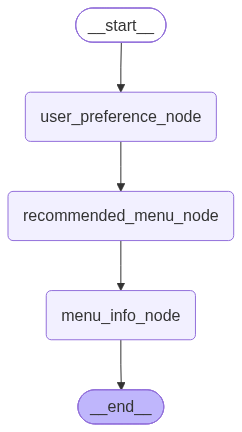

In [16]:
display(Image(graph.get_graph().draw_mermaid_png()))

# 상태 그래프(State Graph) 실행하기

In [17]:
def print_result(result: MenuState):
    print('-' * 100)
    print('선호도: ', result['user_preference'])
    print('추천 메뉴: ', result['recommended_menu'])
    print('메뉴 정보: ', result['menu_info'])
    print('-' * 100)

In [21]:
# 그래프에 입력되는 초기 입력값을 설정한다.
# 첫 번째 노드인 'user_preference_node'는 user_preference() 함수가 무작위로 값을 정해주기 때문에, 지금은 빈 문자열로 초기화만 해서 형식을 맞춘다.
inputs = {'user_preference': ''}

for _ in range(3):
    # invoke() 메소드의 인수로 초기 입력값을 넘겨서 그래프를 실행한다.
    # invoke() 메소드가 실행되면 START 지점에서 시작하여 초기 입력값(inputs)를 가지고 첫 번째 노드(user_preference_node)로 이동한다.
    # 첫 번째 노드로 초기 입력값이 전달되고 무작위로 생성된 사용자 선호도가 MenuState에 저장되고 두 번째 노드(recommended_menu_node)로 이동한다.
    # 두 번째 노드에서 사용자 선호도를 얻어와서 추천 메뉴가 MenuState에 저장되고 세 번째 노드(menu_info_node)로 이동한다.
    # 세 번째 노드에서 추천 메뉴를 얻어와서 메뉴 정보가 MenuState에 저장되고 종료한다.
    result = graph.invoke(inputs)
    print_result(result)

----------------------------------------------------------------------------------------------------
선호도:  해산물
추천 메뉴:  랍스터
메뉴 정보:  랍스터(바닷가재) 요리는 탱글탱글한 식감과 깊은 감칠맛을 지닌 최고급 해산물 요리입니다. 가격: 35,000원
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
선호도:  아무거나
추천 메뉴:  쉐프 특선 메뉴
메뉴 정보:  쉐프가 그날그날 엄선한 특별 요리입니다. 가격: 150,000원
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
선호도:  채식
추천 메뉴:  그린 샐러드
메뉴 정보:  그린 샐러드는 신선한 녹색 잎채소를 주재료로 하여 가벼운 드레싱과 함께 곁들여 먹는 가장 기초적이고 클래식한 샐러드입니다. 가격: 15,000원
----------------------------------------------------------------------------------------------------


# 조건부 엣지 함수로 분기(Branching) 구현하기